In [1]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected")

PyTorch: 2.14.0+cu130
Torchvision: 0.29.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [2]:
import shutil

free_space = shutil.disk_usage(".").free / (1024 ** 3)

print(f"Available disk space: {free_space:.2f} GB")

Available disk space: 256.96 GB


In [3]:
import torchvision
from torchvision.datasets import CIFAR10

# Dataset storage location
data_dir = "./data/cifar10"

# Download training partition
train_dataset = CIFAR10(
    root=data_dir,
    train=True,
    download=True
)

# Download original test partition
test_dataset = CIFAR10(
    root=data_dir,
    train=False,
    download=True
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", train_dataset.classes)
print("Number of classes:", len(train_dataset.classes))
print("Image size:", train_dataset[0][0].size)

Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of classes: 10
Image size: (32, 32)


In [4]:
print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

print("\nClass names:")
print(train_dataset.classes)

image, label = train_dataset[0]

print("\nImage shape:", image.size)
print("First image label:", train_dataset.classes[label])

Training samples: 50000
Test samples: 10000

Class names:
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Image shape: (32, 32)
First image label: frog


In [5]:
import torch
from torch.utils.data import random_split

SEED = 42

generator = torch.Generator().manual_seed(SEED)

train_subset, val_subset = random_split(
    train_dataset,
    [45000, 5000],
    generator=generator
)

print("Training subset:", len(train_subset))
print("Validation subset:", len(val_subset))
print("Test dataset:", len(test_dataset))
print("Random seed:", SEED)

Training subset: 45000
Validation subset: 5000
Test dataset: 10000
Random seed: 42


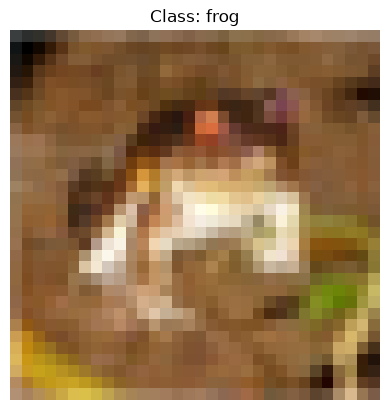

In [6]:
import matplotlib.pyplot as plt

image, label = train_dataset[0]

plt.imshow(image)
plt.title(f"Class: {train_dataset.classes[label]}")
plt.axis("off")
plt.show()


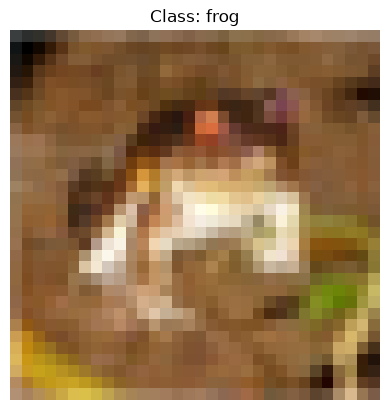

In [7]:
import matplotlib.pyplot as plt

image, label = train_dataset[0]

plt.imshow(image)
plt.title(f"Class: {train_dataset.classes[label]}")
plt.axis("off")
plt.show()

In [8]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

sample_image, sample_label = train_dataset[0]
processed_image = transform(sample_image)

print("Original image size:", sample_image.size)
print("Processed tensor shape:", processed_image.shape)
print("Minimum value:", processed_image.min().item())
print("Maximum value:", processed_image.max().item())

Original image size: (32, 32)
Processed tensor shape: torch.Size([3, 32, 32])
Minimum value: -1.9894737005233765
Maximum value: 2.094278573989868


In [9]:
from torch.utils.data import DataLoader

BATCH_SIZE = 128

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 352
Validation batches: 40
Testing batches: 79


In [10]:
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader, Subset

# Apply preprocessing to training images
transformed_train_dataset = CIFAR10(
    root=data_dir,
    train=True,
    download=False,
    transform=transform
)

# Apply the same preprocessing to test images
transformed_test_dataset = CIFAR10(
    root=data_dir,
    train=False,
    download=False,
    transform=transform
)

# Preserve our existing 45,000 / 5,000 split
train_subset = Subset(
    transformed_train_dataset,
    train_subset.indices
)

val_subset = Subset(
    transformed_train_dataset,
    val_subset.indices
)

test_dataset = transformed_test_dataset

# Create DataLoaders
BATCH_SIZE = 128

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Verify
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])
Training batches: 352
Validation batches: 40
Testing batches: 79


In [11]:
import torch
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)


# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MLP().to(device)

# Check model
print(model)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nTrainable parameters:", total_params)
print("Device:", device)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)

Trainable parameters: 1707274
Device: cuda


In [12]:
# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001


In [13]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # 1. Clear previous gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(images)

        # 3. Calculate loss
        loss = criterion(outputs, labels)

        # 4. Backward pass
        loss.backward()

        # 5. Update weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training function created successfully.")

Training function created successfully.


In [14]:
def evaluate_model(model, data_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Evaluation function created successfully.")

Evaluation function created successfully.


In [15]:
EPOCHS = 10

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate_model(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.2f}%"
    )

Epoch [1/10] | Train Loss: 1.6598 | Train Acc: 41.28% | Val Loss: 1.5559 | Val Acc: 45.14%
Epoch [2/10] | Train Loss: 1.4437 | Train Acc: 49.08% | Val Loss: 1.4543 | Val Acc: 48.64%
Epoch [3/10] | Train Loss: 1.3354 | Train Acc: 53.01% | Val Loss: 1.4067 | Val Acc: 50.20%
Epoch [4/10] | Train Loss: 1.2470 | Train Acc: 55.97% | Val Loss: 1.4214 | Val Acc: 50.94%
Epoch [5/10] | Train Loss: 1.1658 | Train Acc: 58.86% | Val Loss: 1.4310 | Val Acc: 50.26%
Epoch [6/10] | Train Loss: 1.0941 | Train Acc: 61.28% | Val Loss: 1.4331 | Val Acc: 52.18%
Epoch [7/10] | Train Loss: 1.0120 | Train Acc: 64.04% | Val Loss: 1.4743 | Val Acc: 51.30%
Epoch [8/10] | Train Loss: 0.9432 | Train Acc: 66.73% | Val Loss: 1.5320 | Val Acc: 50.64%
Epoch [9/10] | Train Loss: 0.8765 | Train Acc: 69.03% | Val Loss: 1.5797 | Val Acc: 51.48%
Epoch [10/10] | Train Loss: 0.8092 | Train Acc: 71.23% | Val Loss: 1.6056 | Val Acc: 52.48%


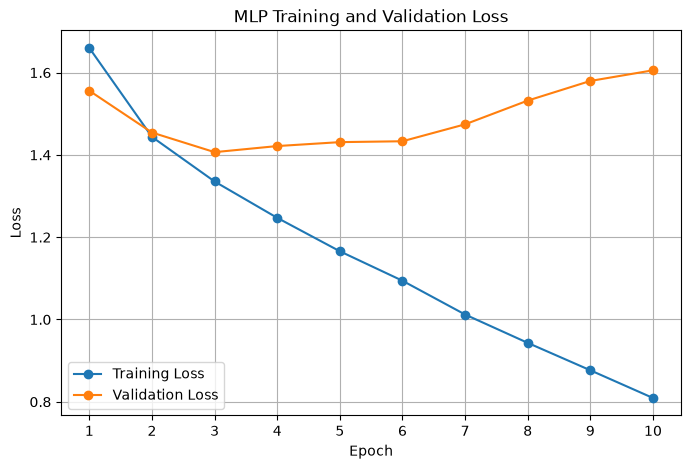

In [16]:
import matplotlib.pyplot as plt

epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")

plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

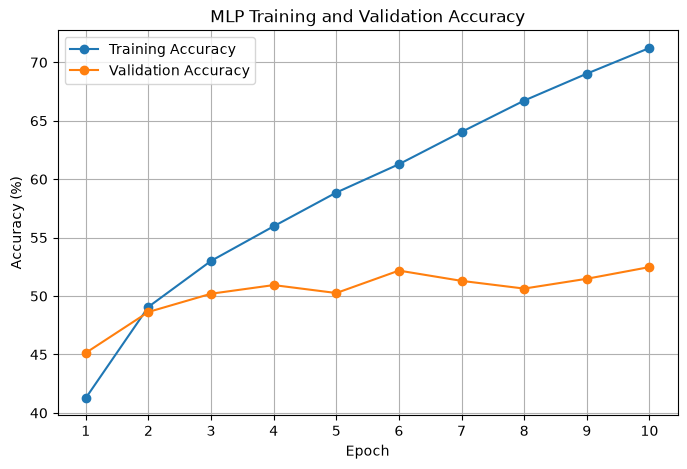

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("MLP Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

In [18]:
test_loss, test_accuracy = evaluate_model(
    model,
    test_loader,
    criterion,
    device
)

print("MLP Final Test Results")
print("----------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

MLP Final Test Results
----------------------
Test Loss: 1.5779
Test Accuracy: 52.94%


In [19]:
import json
from pathlib import Path

results = {
    "model": "MLP",
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": 0.001,
    "optimizer": "Adam",
    "loss_function": "CrossEntropyLoss",
    "trainable_parameters": total_params,
    "final_train_accuracy": history["train_accuracy"][-1],
    "best_validation_accuracy": max(history["val_accuracy"]),
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "history": history
}

output_dir = Path("../experiments/results")
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "mlp_results.json", "w") as file:
    json.dump(results, file, indent=4)

print("MLP results saved successfully.")

MLP results saved successfully.


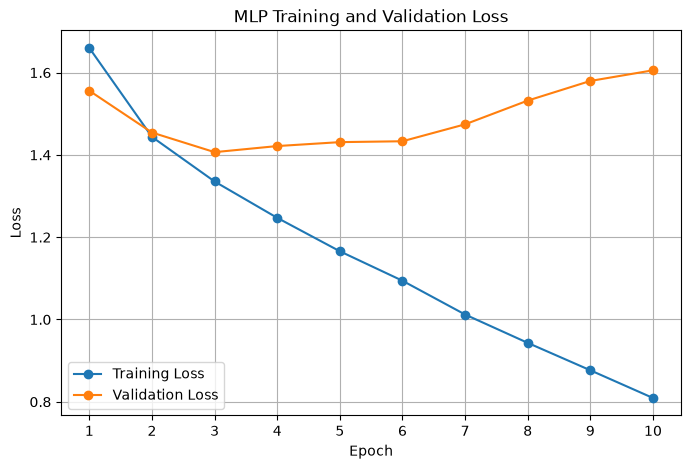

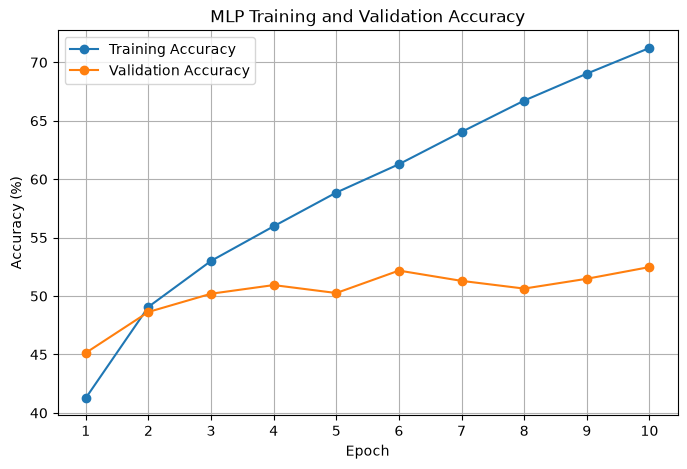

Both MLP graphs saved successfully.


In [20]:
from pathlib import Path
import matplotlib.pyplot as plt

plot_dir = Path("../experiments/plots")
plot_dir.mkdir(parents=True, exist_ok=True)

epochs = range(1, EPOCHS + 1)

# 1. Loss graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.savefig(plot_dir / "mlp_loss.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("MLP Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.savefig(plot_dir / "mlp_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

print("Both MLP graphs saved successfully.")